# ДДЗ-1. Атаки на классификатор при помощи градиента

## Описание лабораторной работы
В данной работе исследуется уязвимость полносвязной нейронной сети перед состязательными атаками (adversarial attacks). Модель обучается классифицировать рукописные цифры из стандартного датасета `scikit-learn` (размер изображений — $8 \times 8$ пикселей, 10 классов). 

Цель работы — программно модифицировать исходные изображения так, чтобы изменения оставались незаметными для человека, но заставляли классификатор выдавать ошибочный ответ.

Обучать сеть вручную не требуется: базовая модель обучается автоматически в первой ячейке. Для реализации атак используются частные производные функции потерь по пикселям входного изображения $\nabla_X L(\theta, X, y)$, вычисляемые автоматически через `backpropagation` в PyTorch.

---

## План выполнения (Структура ноутбука)

*   **Шаг 1. Обучение модели-жертвы (Автоматически)** — запуск готового цикла обучения базового классификатора.
*   **Шаг 2. Атака FGSM (Fast Gradient Sign Method)** — одношаговый сдвиг пикселей на величину $\varepsilon$ в сторону наискорейшего роста ошибки.
*   **Шаг 3. Атака PGD (Projected Gradient Descent)** — итеративный метод из нескольких малых шагов с проецированием результата обратно в допустимую $\varepsilon$-окрестность.
*   **Шаг 4. Атака DeepFool** — поиск минимальной по $L_2$-норме помехи для преодоления границы разделяющей поверхности классов на основе линеаризации модели.
*   **Шаг 5 ★. Targeted Attack (Целевая атака)** — модификация изображения с целью заставить нейросеть выдать конкретный неверный класс (цифру «9»).
*   **Шаг 6 ★★. Adversarial Defense (Защита модели)** — добавление случайного шума на входе для разрушения структуры атаки и оценка падения качества (accuracy) на чистых данных.

---

## Технические особенности и регламент

*   **Вычислительная сложность:** Все вычисления оптимизированы для CPU и занимают несколько секунд, так как размерность входа мала ($64$ признака). 
*   **Требования к оформлению:** 
    *   Заполняйте только программные блоки в ячейках с пометкой `✍️ ДЕЛАЙТЕ`.
    *   Успешное выполнение проверяется автоматическими тестами в ячейках `✅ Самопроверка`.
    *   **Запрещено** переименовать или удалять ключевые переменные окружения: `net`, `acc`, `fgs`, `pgd`, `dfr_ok`, `dfr_l2`, `tts`, `def_acc`, `def_rate`, `rate_plain`.

---

## 0. Данные: 1797 картинок 8×8


тренировка: 1347 | тест: 450 | картинка 8×8 = 64 пикселя


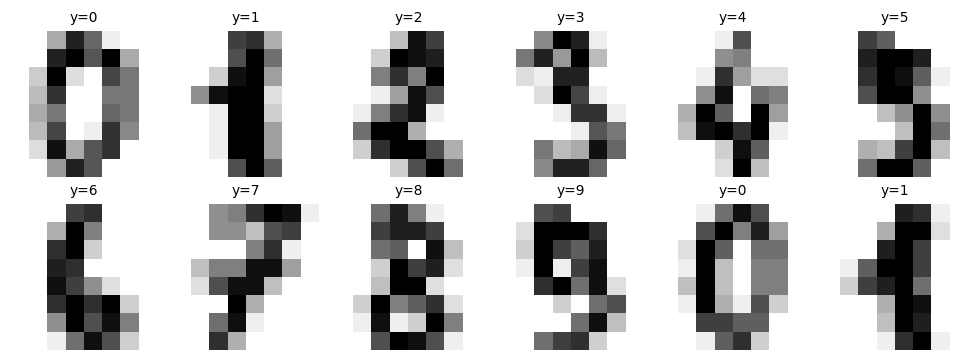

In [1]:
# Данные: цифры 8×8 — наш тренировочный полигон
import sys, time, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sys.stdout.reconfigure(encoding='utf-8', errors='replace')
torch.manual_seed(0)

dd = load_digits()
X, Y = dd.data / 16.0, dd.target                 # 1797 картинок 8×8, пиксели в [0,1]
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=0.25,
                                      random_state=42, stratify=Y)
Xtr = torch.from_numpy(Xtr).float()
Xte = torch.from_numpy(Xte).float()
Ytr = torch.from_numpy(Ytr).long()
Yte = torch.from_numpy(Yte).long()
print(f'тренировка: {len(Xtr)} | тест: {len(Xte)} | картинка 8×8 = 64 пикселя')

fig, axes = plt.subplots(2, 6, figsize=(9, 3.4))
for ax, i in zip(np.ravel(axes), range(12)):
    ax.imshow(X[i].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'y={int(Y[i])}', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 1. Шаг 1 (автоматически): Обучение модели-жертвы

В этой готовой ячейке собирается и обучается компактный полносвязный классификатор. Архитектура сети принимает изображение $8 \times 8$ пикселей, вытянутое в вектор из 64 признаков:

$$\text{Вход (64)} \rightarrow \text{Скрытый слой (32)} \rightarrow \text{Выход (10 классов)}$$

Процесс обучения стандартный: минимизируется функция потерь Cross-Entropy с помощью оптимизатора Adam на протяжении 40 эпох (размер батча — 128 картинок).

### Контрольные показатели
*   **Итоговая метрика:** После завершения цикла обучения на экране отобразится точность (Accuracy) модели на отложенной тестовой выборке.
*   **Ожидаемый результат:** Значение должно зафиксироваться на уровне $\approx 0.97$ ($97\%$ правильных ответов). Все последующие атаки будут оцениваться относительно этого базового качества.

### Концептуальное отличие от процесса обучения
*   **Обычное обучение:** Веса сети $\theta$ изменяются для минимизации ошибки: $\theta \leftarrow \theta - \eta \nabla_\theta L$. Входные данные $X$ заморожены.
*   **Градиентная атака:** Веса сети $\theta$ фиксируются. Градиенты вычисляются по **самому входному изображению $X$**: $\nabla_X L(\theta, X, y)$. Полученный вектор из 64 чисел указывает направление изменения каждого пикселя, при котором ошибка классификации возрастает быстрее всего.

---


In [1]:
# Шаг 1: модель-жертва (готовая ячейка — просто запустите)

torch.manual_seed(0)

net = nn.Sequential(nn.Linear(64, 64), nn.ReLU(),
                    nn.Linear(64, 32), nn.ReLU(),
                    nn.Linear(32, 10))
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
t0 = time.perf_counter()
for ep in range(40):
    perm = torch.randperm(len(Xtr))
    for b in range(0, len(Xtr), 128):
        idx = perm[b:b + 128]
        opt.zero_grad()
        loss = F.cross_entropy(net(Xtr[idx]), Ytr[idx])
        loss.backward()
        opt.step()
secs = time.perf_counter() - t0
print(f'обучение: {secs:.1f}s')

with torch.no_grad():
    acc = float((net(Xte).argmax(1) == Yte).float().mean())
print(f'точность на test: {acc:.4f}')

обучение: 0.8s
точность на test: 0.9689


In [ ]:
# ✅ Самопроверка (Шаг 1): модель обучилась
# ожидает: net, acc
assert acc > 0.95, f'точность {acc:.4f} — модель обучилась плохо (нужно > 0.95)'
print(f'✅ точность на тесте {acc:.4f} — модель готова, начинаем атаки')

In [1]:
# Пул атак: 40 ПРАВИЛЬНО классифицированных примеров
with torch.no_grad():
    pred = net(Xte).argmax(1)
ids = torch.nonzero(pred == Yte).flatten()
ids = ids[torch.randperm(len(ids),
                         generator=torch.Generator().manual_seed(7))[:40]]
Xa, Ya = Xte[ids].clone(), Yte[ids]


def swap_rate(xs, ya):
    """доля атакованных, у которых вердикт сменился"""
    with torch.no_grad():
        return float((net(xs).argmax(1) != ya).float().mean())


print('атак-пул:', tuple(Xa.shape), '| начальная доля подмен:',
      swap_rate(Xa, Ya))

атак-пул: (40, 64) | начальная доля подмен: 0.0


## 2. Шаг 2: FGSM — один шаг вдоль градиента

### Контекст тестирования и метрика эффективности
Из обученной выборки сформирован **атак-пул**: 40 тестовых изображений `Xa` с истинными метками классов `Ya`, которые базовая модель гарантированно классифицирует верно. 

Для оценки успешности взлома используется функция `swap_rate(xs, ya)`. Она вычисляет долю картинок (от 0 до 1), для которых измененный вариант `xs` привел к неверному предсказанию модели. Ваша цель — максимизировать этот показатель при минимальных визуальных искажениях.

---

### Математическая модель FGSM

**FGSM (Fast Gradient Sign Method)** — это классический одношаговый метод генерации состязательных примеров. Вместо минимизации ошибки сети для настройки весов, метод делает один шаг в направлении **максимального роста функции потерь** (Cross-Entropy) по входному изображению:

$$\tilde{x} = x_0 + \varepsilon \cdot \mathrm{sign}\left(\nabla_{x}\,\text{CE}(f(x_0), y)\right)$$

Где:
*   $x_0$ — исходный вектор изображения ($64$ пикселя).
*   $\tilde{x}$ — результирующее состязательное (adversarial) изображение.
*   $\text{CE}(\cdot)$ — функция потерь Cross-Entropy.
*   $f(x_0)$ — логиты (выходы) нейросети для исходной картинки.
*   $y$ — истинный класс изображения.
*   $\nabla_{x}$ — вектор частных производных (градиент) функции потерь по каждому из 64 пикселей.
*   $\varepsilon$ (эпсилон) — **бюджет атаки**. Параметр, определяющий максимальное абсолютное изменение для каждого отдельного пикселя.

#### Почему используется оператор $\mathrm{sign}$ (знак)?
Функция $\mathrm{sign}(\cdot)$ извлекает только направление изменения (+1 или -1) для каждой координаты градиента. Это дает два ключевых преимущества:
1.  **Максимизация возмущения в рамках ограничений:** Каждый пиксель гарантированно сдвигается на максимально допустимую величину $\pm\varepsilon$. Это максимизирует рост ошибки в рамках заданной $L_\infty$-окрестности.
2.  **Визуальная незаметность:** Поскольку изменение строго ограничено значением $\varepsilon$, искажение равномерно распределяется по всей картинке и остается незаметным для человеческого глаза (при малых значениях $\varepsilon$).

---

### Влияние бюджета атаки ($\varepsilon$)
Величина $\varepsilon$ регулирует баланс между незаметностью и агрессивностью атаки:
*   **Слишком малый $\varepsilon$** (например, $0.01$): Картинка визуально идентична оригиналу, но модель легко справляется с шумом. Доля успешных атак близка к 0.
*   **Оптимальный $\varepsilon$** (например, $0.1$ – $0.15$): Картинка практически не изменилась для человека, но нейросеть начинает массово ошибаться.
*   **Слишком большой $\varepsilon$** (например, $0.3$ и выше): Атака становится стопроцентной, однако на изображении появляется отчетливо видимый серый или зернистый шум, нарушающий скрытность.

---

### Практическое задание

Вам необходимо запрограммировать функцию `fgsm` внутри блока `✍️ ДЕЛАЙТЕ`. Проведите эксперимент для шести различных значений бюджета атаки: $\varepsilon \in [0.01, 0.05, 0.1, 0.15, 0.2, 0.3]$.

**Ожидаемое поведение метрик:**
*   При $\varepsilon = 0.01$: показатель `swap_rate` должен быть близок к нулю.
*   При $\varepsilon \ge 0.2$: состязательный шум должен успешно обмануть модель почти на всем атак-пуле (`swap_rate` $\approx 1.0$).



In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 2): FGSM. Функция должна вернуть fgsm(x0, ya, eps) → x̃.

def fgsm(x0, ya, eps):
    # 1) скопируйте x0 с requires_grad_(True)
    x = ...
    # 2) CE(net(x), ya).backward() — градиент по входу
    ...
    # 3) x̃ = clamp(x0 + eps * x.grad.sign(), 0, 1)
    return ...


fgs = {}
for eps in 0.01, 0.03, 0.05, 0.1, 0.2, 0.3:
    xs = ...
    fgs[eps] = ...
    print(f'eps={eps:4.2f}: подмена {fgs[eps]*100:5.1f}%')

In [ ]:
# ✅ Самопроверка (Шаг 2): FGSM ломает модель, на которой она была обучена
# ожидает: fgs (словарь eps → доля подмен), swap_rate
assert fgs[0.2] > 0.90, f'FGSM(0.2) = {fgs[0.2]:.2f} — при большом ε должно ломаться почти всё'
assert fgs[0.1] > 0.30, f'FGSM(0.1) = {fgs[0.1]:.2f} — при малом ε подмен слишком мало'
assert fgs[0.03] < fgs[0.1], 'Доля подмен должна расти вместе с ε'
print(f'✅ FGSM(0.1): {fgs[0.1]*100:.0f}% подмен, FGSM(0.2): {fgs[0.2]*100:.0f}%')

## 3. Шаг 3: PGD — много маленьких шагов с проекцией

### Ограничения одношаговых методов
Метод FGSM выполняет один грубый шаг по градиенту. Из-за нелинейности разделяющей поверхности нейросети один большой шаг может промахнуться мимо оптимальной состязательной точки или натолкнуться на локальные особенности рельефа функции потерь. 

---

### Математическая модель PGD

**PGD (Projected Gradient Descent / Проецируемый градиентный спуск)** решает эту проблему итеративно, адаптируя методы условной оптимизации для генерации состязательных примеров. Вместо одного шага на $\varepsilon$, алгоритм выполняет $T$ последовательных шагов меньшего размера $\alpha$, регулярно возвращая промежуточный результат обратно в допустимую область (проецируя его).

Математически итерационный шаг PGD записывается следующим образом:

$$x^{t+1} = \Pi_{x_0 + \mathcal{S}} \left( x^t + \alpha \cdot \mathrm{sign}\left(\nabla_{x^t}\,\text{CE}(f(x^t), y)\right) \right)$$

Где:
*   $x^t$ — изображение на итерации $t$ (при $x^t = x^0$ в базовом варианте).
*   $\alpha$ — размер промежуточного шага (обычно $\alpha < \varepsilon$).
*   $\Pi$ — оператор проекции на допустимое подмножество.

---

### Алгоритм работы PGD (Пошагово)

1.  **Случайная инициализация (Random Start):** Стартовая точка $x^1$ выбирается случайным образом внутри $\varepsilon$-окрестности исходного изображения: $x^1 = x_0 + \mathcal{U}(-\varepsilon, \varepsilon)$. Это позволяет атаке избежать «застревания» в локальных экстремумах и плато, исследуя разные направления.
2.  **Итеративный сдвиг:** На каждом шаге $t$ вычисляется градиент функции потерь текущего состояния картинки, и пиксели смещаются на малую величину $\alpha$ вдоль знака градиента.
3.  **Двойная проекция (Clip / Clamp):** Вылетевшее за границы ограничений изображение принудительно возвращается обратно:
    *   **Ограничение по бюджету ($L_\infty$-норма):** Отклонение от исходной картинки $x_0$ жестко ограничивается диапазоном $[-\varepsilon, \varepsilon]$ с помощью операции `torch.clamp(x - x0, -eps, eps)`. Это гарантирует визуальную незаметность изменений.
    *   **Ограничение по физическому смыслу:** Значения яркости пикселей обрезаются до диапазона $[0, 1]$, так как пиксели не могут быть темнее абсолютно черного или ярче абсолютно белого.
4.  **Повторение:** Цикл сдвига и проекции повторяется фиксированное число раз (например, $T = 30$).

---

### Почему PGD эффективнее?

За счет множества мелких шагов алгоритм PGD «прощупывает» геометрию пространства потерь вокруг изображения. Он способен огибать сложные изгибы разделяющей поверхности классов и находить состязательные примеры даже глубоко внутри области правильного класса, которые невозможно обнаружить одним линейным шагом FGSM. 

В теории состязательного машинного обучения PGD считается **универсальной атакой первого порядка**: если в заданной $\varepsilon$-окрестности изображения существует точка, способная обмануть сеть, PGD с достаточным числом итераций гарантированно её найдет.

---

### Практическое задание

В блоке `✍️ ДЕЛАЙТЕ` реализуйте функцию `pgd`. Настройте параметры: количество шагов $T = 30$, размер шага $\alpha = \varepsilon / 10$ (или подберите оптимальный эмпирически). Убедитесь с помощью ячейки `✅ Самопроверка`, что при одинаковых значениях бюджета $\varepsilon$ метод PGD демонстрирует значительно более высокий процент успешных подмен (`swap_rate`), чем FGSM.


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 3): PGD. Внутренний шаг почти тот же, что во FGSM,
# но (a) старт случайный, (b) шаг α < eps, (c) проекция в ε-шар вокруг x0.

def pgd(x0, ya, eps, alpha, steps=30):
    x = x0 + torch.randint(0, 2, x0.shape).float() * 2 * eps - eps   # случайный старт
    for _ in range(steps):
        ...
        # шаг по знаку градиента на alpha
        # проекция: |x − x0| ≤ eps, потом clip 0..1
        ...
    return x.detach()


pgd_rates = {}
for eps in 0.05, 0.1, 0.2:
    xs = ...
    pgd_rates[eps] = swap_rate(xs, Ya)
    print(f'eps={eps:4.2f}: подмена {pgd_rates[eps]*100:5.1f}%')
pgd = pgd_rates   # алиас для самопроверки

In [ ]:
# ✅ Самопроверка (Шаг 3): PGD не хуже FGSM при тех же ε
# ожидает: pgd (словарь eps → доля подмен), fgs
assert pgd[0.1] >= fgs[0.1] - 0.02, 'PGD(0.1) должен быть не хуже FGSM(0.1)'
assert pgd[0.05] >= fgs[0.05] - 0.02, 'PGD(0.05) тоже должен быть не хуже FGSM(0.05)'
assert pgd[0.2] > 0.95, f'PGD(0.2) = {pgd[0.2]:.2f} — за 30 шагов должно ломаться почти всё'
print(f'✅ PGD(0.1): {pgd[0.1]*100:.0f}% | PGD(0.2): {pgd[0.2]*100:.0f}%')

## 4. Шаг 4: DeepFool — минимальная помеха

### Концептуальное отличие от FGSM и PGD
Методы FGSM и PGD работают в рамках фиксированного бюджета возмущения ($\varepsilon$), стремясь максимизировать ошибку модели и полностью расходуя этот бюджет. 

**DeepFool** решает строго обратную (оптимизационную) задачу: он ищет **минимальное по норме изменение** входного изображения, которое заставит модель изменить свое предсказание. Бюджет атаки здесь не задается жестко — алгоритм динамически рассчитывает кратчайшее расстояние до разделяющей поверхности классов.

---

### Математическая модель и алгоритм DeepFool

В основе метода лежит **линеаризация разделяющей поверхности** вокруг текущей точки (аналогично методу Ньютона в численных методах). Для многоклассового классификатора алгоритм находит ближайшую гиперплоскость, разделяющую текущий истинный класс $y_0$ и любой другой класс $k$.

Пусть $f_k(x)$ — логит (выход сети до софтмакса) для класса $k$. Разность логитов определяет границу решения. В линейном приближении первого порядка Тейлора расстояние от текущего изображения $x$ до границы класса $k$ вычисляется через отношение разности функций к норме разности их градиентов.

На каждом шаге алгоритма для всех альтернативных классов $k \neq y_0$ рассчитываются:
1.  **Направление сдвига (вектор нормали к границе):**
    $$w_k = \nabla_x f_k(x) - \nabla_x f_{y_0}(x)$$
2.  **Разность выходов:**
    $$f_k = f_k(x) - f_{y_0}(x)$$
3.  **Расстояние до границы:**
    $$\text{dist}_k = \frac{|f_k|}{\|w_k\|_2}$$

Алгоритм выбирает класс $k^*$, до границы с которым расстояние минимально, и вычисляет вектор минимальной помехи $r$:

$$r \leftarrow r + \frac{|f_{k^*}|}{\|w_{k^*}\|_2^2} \cdot w_{k^*}$$

---

### Итерационный цикл DeepFool
1.  Принимается исходное изображение $x = x_0$, вектор накопленной помехи $r = 0$.
2.  Вычисляются логиты и их градиенты по входу для всех 10 классов.
3.  Определяется ближайший класс-мишень $k^*$ на основе минимального расстояния $\text{dist}_k$.
4.  Вектор помехи $r$ обновляется согласно формуле шага.
5.  Промежуточный результат проецируется на физический диапазон яркостей: $\tilde{x} = \text{clamp}(x_0 + r, 0, 1)$.
6.  Шаги 2–5 повторяются до тех пор, пока текущий топ-1 ответ модели на изображении $\tilde{x}$ не изменится (класс предсказания $\neq y_0$). Обычно для успешного взлома хватает 2–5 итераций.

---

### Практическое задание

Реализуйте алгоритм DeepFool в блоке `✍️ ДЕЛАЙТЕ`. Для оценки эффективности метода вам необходимо рассчитать и сравнить среднюю геометрическую длину ($L_2$-норму) полученного вектора помехи $r$ с аналогичными показателями для FGSM и PGD.

**Ожидаемый результат:**
Поскольку DeepFool ищет кратчайший путь до границы смены класса, средняя $L_2$-норма его возмущений должна оказаться **существенно меньше**, чем у FGSM и PGD, при этом обеспечивая стопроцентное изменение ответа модели на тестовом пуле.



In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 4): DeepFool. Каркас написан; «...» — места, где нужен ваш код.

def deepfool(x0, y0, maxit=50):
    r = torch.zeros_like(x0)
    for _ in range(maxit):
        with torch.no_grad():
            logits = net(x0 + r)[0]
            if logits.argmax().item() != y0.item():
                break
        grads = []
        for k in range(10):
            if k == y0.item():
                grads.append(None)
                continue
            xg = (x0 + r).clone().requires_grad_(True)
            net(xg)[0, k].backward()          # градиент logit_k по входу
            grads.append(xg.grad.clone())
        with torch.no_grad():
            # 1) найдите k с минимумом dist_k = |f_k| / ||w_k||  (k != y0)
            ksel = ...
            # 2) дополните r шагом (|f_ksel| / ||w_ksel||^2) * w_ksel
            r = ...
            # 3) проекция r так, чтобы (x0 + r) остался в [0,1]
            r = ...
    return x0 + r, float(r.norm())


dfr_ok, l2_list = 0, []
for i in range(12):
    xa, r_norm = deepfool(Xa[i:i + 1], Ya[i:i + 1])
    with torch.no_grad():
        if net(xa).argmax().item() != Ya[i].item():
            dfr_ok += 1
    l2_list.append(r_norm)
dfr_l2 = float(np.mean(l2_list))
print(f'DeepFool: подмен {dfr_ok}/12 | средняя L2 помехи = {dfr_l2:.3f}')

In [ ]:
# ✅ Самопроверка (Шаг 4): минимальная помеха действительно минимальная
# ожидает: dfr_ok, dfr_l2
assert dfr_ok >= 7, f'подмен только {dfr_ok}/12 — проверьте DeepFool'
assert dfr_l2 < 1.0, f'L2 = {dfr_l2:.3f} — помеха слишком большая для «минимальной»'
print(f'✅ DeepFool: {dfr_ok}/12 подмен, средняя L2 помехи = {dfr_l2:.3f}')

## 5. Шаг 5 (★): Целевая атака — принудительный выбор класса «9»

### Нецелевые vs. Целевые атаки
Все предыдущие алгоритмы (FGSM, PGD, DeepFool) относились к классу **нецелевых атак (untargeted)**. Их единственная задача — максимизировать ошибку классификатора, вынудив его выдать любой ошибочный класс, отличный от истинного $y$.

**Целевая атака (targeted attack)** — это значительно более опасный и сложный сценарий. Злоумышленник стремится не просто сломать модель, а заставить её выдать конкретный, заранее определенный неверный ответ $y_{\text{target}}$. В реальных системах компьютерного зрения это критическая уязвимость (например, когда дорожный знак «Стоп» распознается автопилотом как «Ограничение скорости 80»).

---

### Математическая модель целевой атаки PGD

Для реализации целевой атаки базовая схема итеративного алгоритма PGD адаптируется под оптимизационную задачу минимизации. Вместо увеличения ошибки на истинном классе, мы **минимизируем функцию потерь относительно целевого класса**.

Математический шаг целевого PGD принимает следующий вид:

$$x^{t+1} = \Pi_{x_0 + \mathcal{S}} \left( x^t - \alpha \cdot \mathrm{sign}\left(\nabla_{x^t}\,\text{CE}(f(x^t), y_{\text{target}})\right) \right)$$

Где:
*   $y_{\text{target}} = 9$ — целевой класс для всего атак-пула.
*   Знак **минус ($-$)** перед размером шага меняет градиентный подъем на классический **градиентный спуск (gradient descent)**, направляя траекторию изменений в сторону минимума функции потерь для целевого класса.

---

### Алгоритм работы и ограничения бюджета

1.  **Функция потерь:** Вычисляется Cross-Entropy между текущими логитами модели $f(x^t)$ и целевым тензором, целиком заполненным метками `9`.
2.  **Шаг оптимизации:** Пиксели сдвигаются **против** направления градиента знака.
3.  **Проекция и Clamp:** На каждой итерации промежуточное изображение проецируется обратно в $L_\infty$-окрестность радиуса $\varepsilon$ относительно исходной картинки $x_0$ и обрезается до физических границ яркости $[0, 1]$.

#### Особенности бюджета атаки
Бюджет атаки для этого шага увеличен до **$\varepsilon = 0.25$**. Навязать модели конкретное неверное решение математически труднее, чем просто сбить её с толку. Сети необходимо «нарисовать» поверх исходной структуры скрытые признаки девятки, способные перевесить признаки оригинальной цифры, что требует большей амплитуды возмущений.

---

### Практическое задание

В блоке `✍️ ДЕЛАЙТЕ` запрограммируйте целевую модификацию алгоритма PGD. В качестве метрики успешности используйте долю картинок из пула, для которых модель выдала предсказание, строго равное 9 (переменная `tts`). Ваша цель — добиться высокой результативности целевого взлома при сохранении ограничений на видимый шум.


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 5, ★): targeted-PGD.

def pgd_targeted(x0, y_tgt, eps, alpha, steps=40):
    x = x0 + torch.randint(0, 2, x0.shape).float() * 2 * eps - eps
    for _ in range(steps):
        ...
        # ШАГ ВНУТРЬ цели: x = x - alpha * grad.sign()
        ...
    return x.detach()


tts, N_T = 0, 24
for i in range(N_T):
    xt = ...
    with torch.no_grad():
        if net(xt).argmax().item() == 9:
            tts += 1
print(f'targeted→9 (eps=0.25): успех {tts}/{N_T}')

In [ ]:
# ✅ Самопроверка (Шаг 5, ★): целенаправленная подмена работает
# ожидает: tts
assert tts >= 12, f'успешных {tts}/24 — целевая атака слишком слабая'
print(f'✅ targeted→9: {tts}/24 ({tts/24*100:.0f}%)')

## 6. Шаг 6 (★★): Защита — случайный шум на входе

### Механизм защиты (Adversarial Defense)
Один из самых простых и вычислительно дешевых способов защиты — добавление случайного (обычно гауссова) шума ко входному изображению непосредственно перед его подачей в нейросеть:

$$\tilde{x}_{\text{defended}} = x + \eta, \quad \text{где } \eta \sim \mathcal{N}(0, \sigma^2)$$

Где:
*   $x$ — входное изображение (чистое или уже содержащее состязательную помеху).
*   $\sigma$ — стандартное отклонение шума, определяющее его интенсивность.

#### Почему это работает против атак?
Состязательные помехи (особенно от таких методов, как FGSM или PGD) математически точно выверяются под конкретную геометрию разделяющей поверхности и текущую точку в пространстве признаков. Случайный шум при каждом новом вызове модели непредсказуемо сдвигает изображение в случайном направлении. В результате ювелирно подстроенный вектор атаки «размывается», перестает дотягивать до границы классов, и доля успешных взломов падает.

---

### Цена защиты (Компромисс)
У данного метода есть явный побочный эффект: случайный шум искажает не только атакованные изображения, но и полезные признаки на обычных картинках. Это приводит к компромиссу (trade-off) между безопасностью и качеством работы модели:

*   **Низкий уровень шума ($\sigma \to 0$):** Модель сохраняет исходную высокую точность на чистых данных, но остается уязвимой для состязательных атак.
*   **Высокий уровень шума ($\sigma \gg 0$):** Атаки полностью нейтрализуются, однако нейросеть перестает распознавать даже простые чистые изображения из-за сильного искажения полезного сигнала.

---

### Практическое задание

В блоке `✍️ ДЕЛАЙТЕ` вам необходимо реализовать добавление случайного шума с тремя уровнями интенсивности: $\sigma \in \{0.05, 0.10, 0.20\}$. Для каждого значения $\sigma$ измерьте два ключевых показателя:

1.  **Точность на чистых данных (`def_acc`):** Процент правильных ответов модели на оригинальном тестовом наборе при включенном зашумлении. Это показатель того, «во что обошлась» защита.
2.  **Эффективность против атаки (`def_rate`):** Доля успешных подмен (`swap_rate`) для атаки FGSM с бюджетом $\varepsilon = 0.1$, когда модель защищена шумом.

По итогам эксперимента сравните полученные метрики с базовой точностью без защиты (`rate_plain`) и проанализируйте, при каком значении $\sigma$ достигается наилучший баланс между устойчивостью к взлому и сохранением качества классификации.


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 6, ★★): защита шумом.

sig_grid = 0.05, 0.10, 0.20
rate_plain = fgs[0.1]


def defend(X, sig, gen):
    # шум N(0, sig^2), потом clip(0,1)
    return ...


def_acc, def_rate = {}, {}
xs_nodef = torch.cat([fgsm(Xa[i:i + 1], Ya[i:i + 1], 0.1)
                      for i in range(len(Xa))])
for sig in sig_grid:
    gen = torch.Generator().manual_seed(3)
    ...
    print(f'σ={sig}: чистые под шумом {def_acc[sig]:.4f} | FGSM(0.1) под защитой '
          f'{def_rate[sig]*100:5.1f}%  (без защиты {rate_plain*100:.1f}%)')

In [ ]:
# ✅ Самопроверка (Шаг 6, ★★): защита мешает атаке и не портит чистую точность
# ожидает: def_acc, def_rate, rate_plain
assert def_rate[0.1] < 0.9 * rate_plain,     f'FGSM-подмены не упали заметно ({def_rate[0.1]:.2f} vs {rate_plain:.2f})'
assert def_acc[0.1] >= 0.90, 'точность на чистых примерах под защитой упала ниже 0.90'
print(f'✅ защита σ=0.1: FGSM {def_rate[0.1]*100:.0f}% вместо '
      f'{rate_plain*100:.0f}%; чистые примеры держат {def_acc[0.1]:.4f}')